In [ ]:
import pandas as pd
import numpy as np

import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

In [ ]:
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

data = pd.read_csv("/content/pima-indians-diabetes.data.csv",
                   header = None,
                   names = columns
)

print(data.head())


   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [ ]:
print(data.tail())

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
763                     0.171   63        0  
764                     0.340   27        0  
765                     0.245   30        0  
766                     0.349   47        1  
767                     0.315   23        0  


In [ ]:
print(data.columns)

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [ ]:
print(data.shape)

(768, 9)


In [ ]:
print(data.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [ ]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [ ]:
print(data.dtypes)

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [ ]:
print("Number of duplicate rows: ", data.duplicated().sum())

Number of duplicate rows:  0


In [ ]:
data = data.drop_duplicates()
print("Shape after removing duplicates: ", data.shape)

Shape after removing duplicates:  (768, 9)


In [ ]:
print(data.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
print((data == 0).sum())

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [ ]:
invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

data[invalid_zero_columns] = data[invalid_zero_columns].replace(0, np.nan)

print(data.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
missing_values = data.isnull().sum()
print(missing_values)

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
missing_percentage = (
    data.isnull().sum() / len(data)
) * 100

print(missing_percentage)

Pregnancies                  0.000000
Glucose                      0.651042
BloodPressure                4.557292
SkinThickness               29.557292
Insulin                     48.697917
BMI                          1.432292
DiabetesPedigreeFunction     0.000000
Age                          0.000000
Outcome                      0.000000
dtype: float64


In [ ]:
for column in invalid_zero_columns:
  data[column] = data[column].fillna(
      data[column].median()
  )
print(data.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
print("Missing Values: ")
print(data.isnull().sum())

print("\nCleaned data: ")
print(data.head())

print("\nUpdated statistics: ")
print(data.describe())

Missing Values: 
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Cleaned data: 
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0    125.0  33.6   
1            1     85.0           66.0           29.0    125.0  26.6   
2            8    183.0           64.0           29.0    125.0  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   3

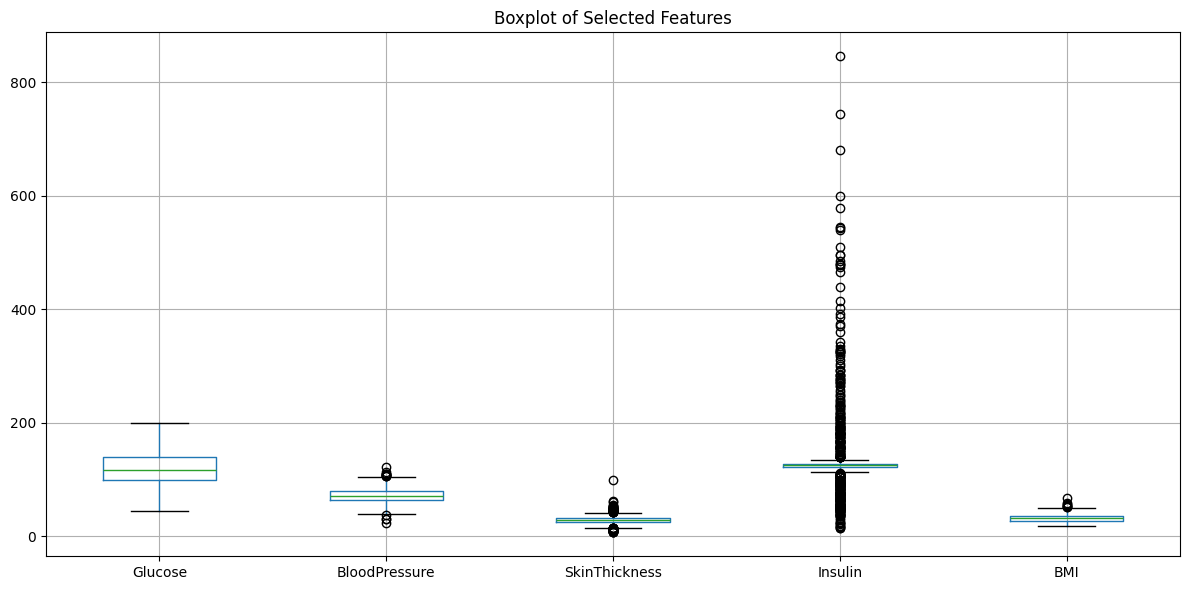

In [ ]:
import matplotlib.pyplot as plt

data[invalid_zero_columns].boxplot(figsize=(12,6))
# plt.xticks(rotations = 45)
plt.title("Boxplot of Selected Features")
plt.tight_layout()
plt.show()

In [ ]:
X = data.drop("Outcome", axis=1)
y = data["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


In [ ]:
print(y.value_counts())
print(y.value_counts(normalize=True) * 100)

Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
    )

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(
    X_train_scaled,
    y_train
    )

LogisticRegression(max_iter=1000)

In [ ]:
y_pred_lr = logistic_model.predict(
    X_test_scaled
    )

In [ ]:
accuracy_lr = accuracy_score(
  y_test,
  y_pred_lr
  )

print("Logistic Regression Accuracy:",
accuracy_lr * 100, "%")

Logistic Regression Accuracy: 70.77922077922078 %


In [ ]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(
    X_test_scaled
)

accuracy_knn = accuracy_score(
    y_test,
    y_pred_knn
)

print("KNN Accuracy:", accuracy_knn * 100, "%")

KNN Accuracy: 75.32467532467533 %


In [ ]:
nb_model = GaussianNB()

nb_model.fit(
    X_train_scaled,
    y_train
)

y_pred_nb = nb_model.predict(
    X_test_scaled
)

accuracy_nb = accuracy_score(
    y_test,
    y_pred_nb
)

print("Naive Bayes Accuracy:", accuracy_nb * 100, "%")

Naive Bayes Accuracy: 70.12987012987013 %


In [ ]:
results = pd.DataFrame({
"Algorithm": [
    "Logistic Regression",
    "KNN",
    "Naive Bayes"
    ],
                         "Accuracy (%)": [
                             accuracy_lr * 100,
                            accuracy_knn * 100,
                            accuracy_nb * 100
                             ]
                         })
print(results)

             Algorithm  Accuracy (%)
0  Logistic Regression     70.779221
1                  KNN     75.324675
2          Naive Bayes     70.129870


In [ ]:
best_algorithm = results.loc[
     results["Accuracy (%)"].idxmax()
    ]

print("Best algorithm based on accuracy:")
print(best_algorithm)

Best algorithm based on accuracy:
Algorithm             KNN
Accuracy (%)    75.324675
Name: 1, dtype: object


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score

# 1. Column names
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

# 2. Load raw CSV
data = pd.read_csv(
    "pima-indians-diabetes.data.csv",
    header=None,
    names=columns
)

# 3. Inspect the dataset
print("Shape:", data.shape)

print("\nData types:")
print(data.dtypes)

print("\nSummary:")
print(data.describe())

print("\nDuplicate rows:", data.duplicated().sum())

# 4. Remove duplicate rows
data = data.drop_duplicates()

# 5. Columns where zero represents invalid or missing data
invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("\nZero counts before cleaning:")
print((data == 0).sum())

# 6. Convert invalid zeros to NaN
data[invalid_zero_columns] = data[
    invalid_zero_columns
].replace(0, np.nan)

# 7. Check missing values
print("\nMissing values before imputation:")
print(data.isnull().sum())

# 8. Median imputation
for column in invalid_zero_columns:
    data[column] = data[column].fillna(
        data[column].median()
    )

# 9. Verify cleaning
print("\nMissing values after imputation:")
print(data.isnull().sum())

# 10. Features and target
X = data.drop("Outcome", axis=1)
y = data["Outcome"]

# 11. Train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 12. Feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 13. Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = logistic_model.predict(X_test_scaled)

accuracy_lr = accuracy_score(
    y_test,
    y_pred_lr
)

# 14. K-Nearest Neighbors (KNN)
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(X_test_scaled)

accuracy_knn = accuracy_score(
    y_test,
    y_pred_knn
)

# 15. Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(
    X_train_scaled,
    y_train
)

y_pred_nb = nb_model.predict(X_test_scaled)

accuracy_nb = accuracy_score(
    y_test,
    y_pred_nb
)

# 16. Compare model accuracies
results = pd.DataFrame({
    "Algorithm": [
        "Logistic Regression",
        "KNN",
        "Naive Bayes"
    ],
    "Accuracy (%)": [
        accuracy_lr * 100,
        accuracy_knn * 100,
        accuracy_nb * 100
    ]
})

print("\nFinal Results:")
print(results)

Shape: (768, 9)

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Summary:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000